# 1. Install All Libraries

In [ ]:
# Install required libraries
!pip install pandas numpy scikit-learn xgboost matplotlib seaborn

# 2. Import All Libraries

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Load Dataset

In [3]:
df = pd.read_csv("credit.csv")

# (IGNORE) 4. Drop Unecessary Columns

In [4]:
#df.drop(columns=[df.columns[0], 'AcountNumber', 'CVV', 'Customer_City_Address'], inplace=True)

# 5. Handle Missing Values

In [5]:
df['CustomerAge'].fillna(df['CustomerAge'].median(), inplace=True)

/tmp/ipython-input-946081727.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['CustomerAge'].fillna(df['CustomerAge'].median(), inplace=True)


# 6. Encode categorical variables

In [6]:
categorical_cols = ['Gender', 'Marital Status', 'CardColour', 'CardType', 'Domain']
df[categorical_cols] = df[categorical_cols].apply(lambda col: LabelEncoder().fit_transform(col))

# 7. Define features and target

In [7]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# 8. Scale features

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 9. Split into train/test (80/20)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 10. Train XGBoost model

In [10]:
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [01:19:52] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

# 11. Evaluate model

In [11]:
from sklearn.metrics import roc_auc_score
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("AUC: ", round(roc_auc_score(y_test, y_proba), 3))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Test Accuracy: 0.86
AUC:  0.945
Confusion Matrix:
 [[1596  425]
 [ 617 4782]]
Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.79      0.75      2021
           1       0.92      0.89      0.90      5399

    accuracy                           0.86      7420
   macro avg       0.82      0.84      0.83      7420
weighted avg       0.86      0.86      0.86      7420



# 12. Plot confusion matrix

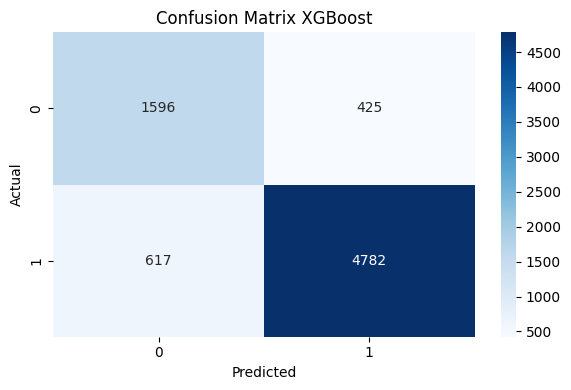

In [12]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix XGBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# 13. Plot ROC Curve

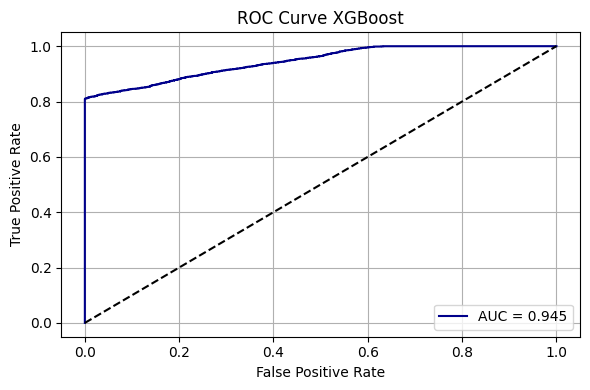

In [13]:
from sklearn.metrics import roc_curve

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Plot ROC curve
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"AUC = {round(roc_auc_score(y_test, y_proba), 3)}", color='darkblue')
plt.plot([0, 1], [0, 1], linestyle='--', color='black')  # Diagonal line
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve XGBoost")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()